# 1. Primera práctica: generación y análisis de datos sintéticos en Python

**¿Qué vamos a hacer?** Crearemos una tabla ficticia de 50.000 pedidos, examinaremos su estructura, prepararemos fechas y montos, resumiremos los datos por mes y región, calcularemos una variación porcentual y representaremos los resultados con gráficos. **El objetivo es aprender Python para análisis de datos**, no estudiar gestión comercial.

Seguiremos una secuencia única: **crear → explorar → preparar → agrupar → comparar → graficar → comprobar**.

## 1.1 Instalación e importación de bibliotecas

Python dispone de bibliotecas que amplían sus funciones. Utilizaremos **NumPy** para generar valores aleatorios, **pandas** para trabajar con tablas y fechas, y **Matplotlib** para crear gráficos.

Si aún no las tienes instaladas, ejecuta esta instrucción **en la terminal del proyecto** (no en un bloque de Python). Quarto la muestra como referencia, sin ejecutarla:

```bash
python -m pip install numpy pandas matplotlib jupyter
```

El documento usa un kernel de Jupyter (`jupyter: python3`). Las bibliotecas se importan una sola vez al inicio y quedan disponibles en los bloques siguientes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1.2 Crear nuestro conjunto de datos

**Propósito:** generar una tabla llamada `datos_ventas` con **50.000 filas y 12 columnas**, sin depender de un archivo externo. Las fechas y los montos se guardarán inicialmente como texto para practicar después su conversión.

Las variables son: `id_pedido`, `fecha_pedido`, `region`, `monto_venta`, `tipo_cliente`, `categoria_producto`, `cantidad`, `porcentaje_descuento`, `costo_envio`, `metodo_pago`, `id_vendedor` y `estado_pedido`.

In [2]:
generador = np.random.default_rng(123)
n_registros = 50000

fechas_simuladas = pd.date_range("2025-01-01", "2026-12-31", freq="D")

datos_ventas = pd.DataFrame({
    "id_pedido": [f"ORD-{i:06d}" for i in range(1, n_registros + 1)],
    "fecha_pedido": pd.DatetimeIndex(generador.choice(fechas_simuladas, n_registros)).strftime("%Y-%m-%d"),
    "region": generador.choice(
        ["Norte", "Sur", "Centro", "Oriente", "Occidente"], n_registros
    ),
    "monto_venta": [
        f"${valor:,.2f}"
        for valor in np.round(generador.uniform(50, 5000, n_registros), 2)
    ],
    "tipo_cliente": generador.choice(
        ["Corporativo", "Individual", "Pyme", "Gobierno"], n_registros
    ),
    "categoria_producto": generador.choice(
        ["Tecnología", "Insumos", "Servicios", "Equipos"], n_registros
    ),
    "cantidad": generador.integers(1, 21, n_registros),
    "porcentaje_descuento": [
        f"{valor}%"
        for valor in generador.choice([0, 5, 10, 15, 20], n_registros)
    ],
    "costo_envio": [
        f"${valor:.2f}"
        for valor in np.round(generador.uniform(5, 150, n_registros), 2)
    ],
    "metodo_pago": generador.choice(
        ["Tarjeta de Crédito", "Transferencia", "Factura 30 días"], n_registros
    ),
    "id_vendedor": [
        f"REP-{valor}"
        for valor in generador.integers(100, 151, n_registros)
    ],
    "estado_pedido": generador.choice(
        ["Completado", "Enviado", "Procesando"],
        n_registros,
        p=[0.80, 0.15, 0.05]
    )
})

In [3]:
datos_ventas

,id_pedido,fecha_pedido,region,monto_venta,tipo_cliente,categoria_producto,cantidad,porcentaje_descuento,costo_envio,metodo_pago,id_vendedor,estado_pedido
0,ORD-000001,2025-01-12,Norte,$379.06,Pyme,Equipos,10,5%,$35.14,Transferencia,REP-114,Completado
1,ORD-000002,2026-05-14,Norte,"$4,873.64",Corporativo,Servicios,12,20%,$126.53,Factura 30 días,REP-112,Completado
2,ORD-000003,2026-03-09,Sur,$347.91,Pyme,Insumos,16,5%,$55.70,Factura 30 días,REP-113,Completado
3,ORD-000004,2025-02-09,Oriente,"$4,133.38",Individual,Equipos,17,5%,$21.09,Factura 30 días,REP-137,Enviado
4,ORD-000005,2026-10-26,Oriente,"$3,081.67",Pyme,Insumos,13,15%,$59.36,Tarjeta de Crédito,REP-122,Completado
...,...,...,...,...,...,...,...,...,...,...,...,...
49995,ORD-049996,2025-01-07,Centro,"$3,908.87",Gobierno,Tecnología,10,15%,$19.55,Transferencia,REP-114,Completado
49996,ORD-049997,2025-06-22,Oriente,"$2,014.95",Corporativo,Equipos,12,20%,$108.09,Factura 30 días,REP-115,Completado
49997,ORD-049998,2026-04-20,Occidente,"$2,504.05",Pyme,Servicios,10,5%,$116.31,Transferencia,REP-112,Completado
49998,ORD-049999,2025-01-21,Norte,$113.76,Individual,Insumos,15,0%,$107.15,Tarjeta de Crédito,REP-126,Completado


**¿Qué significan las instrucciones principales?**

| Función o expresión | ¿Para qué la usamos? |
|:--|:--|
| `np.random.default_rng(123)` | Crea un generador aleatorio reproducible. |
| `pd.DataFrame()` | Construye una tabla con columnas. |
| `pd.date_range()` | Genera el conjunto de fechas posibles. |
| `generador.choice()` | Selecciona valores aleatoriamente, permitiendo repeticiones. |
| `p=[0.80, 0.15, 0.05]` | Define las probabilidades de los tres estados; no fija cantidades exactas. |
| `generador.uniform()` | Genera números aleatorios en un intervalo. |
| `generador.integers()` | Genera números enteros aleatorios. |
| `f"${valor:,.2f}"` | Convierte un monto en texto con símbolo monetario, separador de miles y dos decimales. |

> **Nota:**
Cada fila representa un pedido distinto y `id_pedido` es único. Los montos se generan de forma independiente de la cantidad y el descuento. El estado «Completado» se usará como filtro del ejercicio, pero no significa necesariamente que el pedido esté pagado.
## 1.3 Explorar la estructura de la tabla

**Propósito:** observar el tamaño de la tabla, sus primeras filas y los tipos de datos antes de modificarla.

In [4]:
print("Filas y columnas:", datos_ventas.shape)
print("\nPrimeros registros:")
print(datos_ventas.head())
print("\nEstructura y tipos:")
datos_ventas.info()

Filas y columnas: (50000, 12)

Primeros registros:
    id_pedido fecha_pedido   region monto_venta tipo_cliente  \
0  ORD-000001   2025-01-12    Norte     $379.06         Pyme   
1  ORD-000002   2026-05-14    Norte   $4,873.64  Corporativo   
2  ORD-000003   2026-03-09      Sur     $347.91         Pyme   
3  ORD-000004   2025-02-09  Oriente   $4,133.38   Individual   
4  ORD-000005   2026-10-26  Oriente   $3,081.67         Pyme   

  categoria_producto  cantidad porcentaje_descuento costo_envio  \
0            Equipos        10                   5%      $35.14   
1          Servicios        12                  20%     $126.53   
2            Insumos        16                   5%      $55.70   
3            Equipos        17                   5%      $21.09   
4            Insumos        13                  15%      $59.36   

          metodo_pago id_vendedor estado_pedido  
0       Transferencia     REP-114    Completado  
1     Factura 30 días     REP-112    Completado  
2     Factu

**¿Qué debes observar?** `shape` devuelve `(50000, 12)`. `head()` muestra las primeras cinco filas y `info()` presenta las columnas, el número de valores no nulos y los tipos de datos. Las fechas y los montos aparecen inicialmente como texto (`object` o `str`), por eso los convertiremos.

## 1.4 Preparar las variables para analizarlas

**Propósito:** transformar los montos de texto en números, convertir las fechas y obtener el mes de cada pedido. Guardaremos los cambios en `datos_limpios` para conservar la tabla original.

In [6]:
datos_limpios = datos_ventas.copy()

datos_limpios["monto_venta_numerico"] = pd.to_numeric(
    datos_limpios["monto_venta"].str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

datos_limpios["fecha_pedido_convertida"] = pd.to_datetime(
    datos_limpios["fecha_pedido"], format="%Y-%m-%d", errors="coerce"
)

datos_limpios["mes"] = datos_limpios[
    "fecha_pedido_convertida"
].dt.to_period("M").dt.to_timestamp()

print(datos_limpios[[
    "monto_venta", "monto_venta_numerico",
    "fecha_pedido", "fecha_pedido_convertida", "mes"
]].head())

  monto_venta  monto_venta_numerico fecha_pedido fecha_pedido_convertida  \
0     $379.06                379.06   2025-01-12              2025-01-12   
1   $4,873.64               4873.64   2026-05-14              2026-05-14   
2     $347.91                347.91   2026-03-09              2026-03-09   
3   $4,133.38               4133.38   2025-02-09              2025-02-09   
4   $3,081.67               3081.67   2026-10-26              2026-10-26   

         mes  
0 2025-01-01  
1 2026-05-01  
2 2026-03-01  
3 2025-02-01  
4 2026-10-01  


`copy()` evita modificar la tabla original. `str.replace()` elimina el símbolo `$` y las comas; `pd.to_numeric()` convierte el resultado a número. `pd.to_datetime()` transforma el texto en fecha y `dt.to_period("M").dt.to_timestamp()` representa cada mes por su primer día.

> **Importante:**
Esta es una **primera preparación de tipos**, no una limpieza exhaustiva. `errors="coerce"` convierte a valores faltantes (`NaN` o `NaT`) los datos que no se puedan interpretar. Más adelante aprenderemos a identificarlos y tratarlos.
## 1.5 Obtener un resumen mensual por región

**Propósito:** pasar de pedidos individuales a una tabla más pequeña. Seleccionamos los pedidos completados, agrupamos por mes y región y calculamos el monto total y el número de pedidos.

In [7]:
ventas_mensuales = (
    datos_limpios.loc[datos_limpios["estado_pedido"] == "Completado"]
    .groupby(["mes", "region"], as_index=False)
    .agg(
        monto_total=("monto_venta_numerico", "sum"),
        total_pedidos=("id_pedido", "nunique")
    )
)

print(ventas_mensuales.head())

         mes     region  monto_total  total_pedidos
0 2025-01-01     Centro    854085.30            335
1 2025-01-01      Norte    819708.99            329
2 2025-01-01  Occidente    864728.84            361
3 2025-01-01    Oriente    931757.56            355
4 2025-01-01        Sur    772379.78            307


`loc[]` filtra filas según una condición. `groupby()` forma grupos por mes y región. `agg()` calcula los indicadores de cada grupo: `sum` suma los montos y `nunique` cuenta los identificadores diferentes.

**Cómo leer la salida:** cada fila representa una combinación de mes y región, no un pedido individual.

## 1.6 Calcular el crecimiento mes a mes (MoM %)

**Propósito:** comparar el monto de cada mes con el del mes anterior **dentro de la misma región**. El crecimiento mes a mes (MoM) es una variación porcentual.

$$
\text{MoM (\%)} =
\frac{\text{Monto actual} - \text{Monto anterior}}
{\text{Monto anterior}} \times 100
$$

In [8]:
analisis_crecimiento_mensual = ventas_mensuales.sort_values(
    ["region", "mes"]
).copy()

analisis_crecimiento_mensual["monto_mes_anterior"] = (
    analisis_crecimiento_mensual.groupby("region")["monto_total"].shift(1)
)

monto_anterior = analisis_crecimiento_mensual["monto_mes_anterior"]

analisis_crecimiento_mensual["crecimiento_mensual_pct"] = (
    (
        (analisis_crecimiento_mensual["monto_total"] - monto_anterior)
        / monto_anterior.where(monto_anterior != 0)
    ) * 100
).round(2)

print(analisis_crecimiento_mensual.head(12))

          mes  region  monto_total  total_pedidos  monto_mes_anterior  \
0  2025-01-01  Centro    854085.30            335                 NaN   
5  2025-02-01  Centro    801165.77            308           854085.30   
10 2025-03-01  Centro    876069.34            339           801165.77   
15 2025-04-01  Centro    945541.23            368           876069.34   
20 2025-05-01  Centro    838622.17            346           945541.23   
25 2025-06-01  Centro    823244.90            325           838622.17   
30 2025-07-01  Centro    901527.87            356           823244.90   
35 2025-08-01  Centro    853387.37            354           901527.87   
40 2025-09-01  Centro    846335.84            341           853387.37   
45 2025-10-01  Centro    980381.77            371           846335.84   
50 2025-11-01  Centro    819319.39            315           980381.77   
55 2025-12-01  Centro    725990.68            301           819319.39   

    crecimiento_mensual_pct  
0                   

`sort_values()` ordena los datos, `groupby("region")` separa las comparaciones por región, `shift(1)` recupera el valor del período anterior y `round(2)` redondea a dos decimales. El primer mes de cada región no tiene un mes previo, por lo que su variación aparece como `NaN`.

Un resultado positivo indica aumento y uno negativo indica disminución. Como los datos son simulados, esas variaciones no prueban una tendencia comercial real.

## 1.7 Representar los resultados mediante gráficos

**Propósito:** aprender a visualizar categorías, series temporales y variaciones porcentuales con Matplotlib. Los gráficos usan los mismos datos que ya calculamos.

### Gráfico 1. Cantidad de pedidos por estado

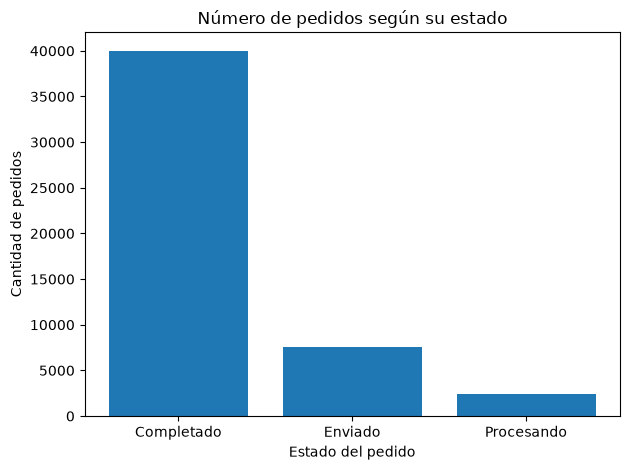

In [9]:
conteo_estados = datos_ventas["estado_pedido"].value_counts().reindex(
    ["Completado", "Enviado", "Procesando"]
)

fig, ax = plt.subplots()
ax.bar(conteo_estados.index, conteo_estados.values)
ax.set(
    title="Número de pedidos según su estado",
    xlabel="Estado del pedido",
    ylabel="Cantidad de pedidos"
)
fig.tight_layout()
plt.show()

**Interpretación:** cada barra muestra cuántos pedidos pertenecen a un estado. «Completado» debería ser la categoría más frecuente porque le asignamos una probabilidad del 80 % al generar los datos.

### Gráfico 2. Evolución mensual del monto por región

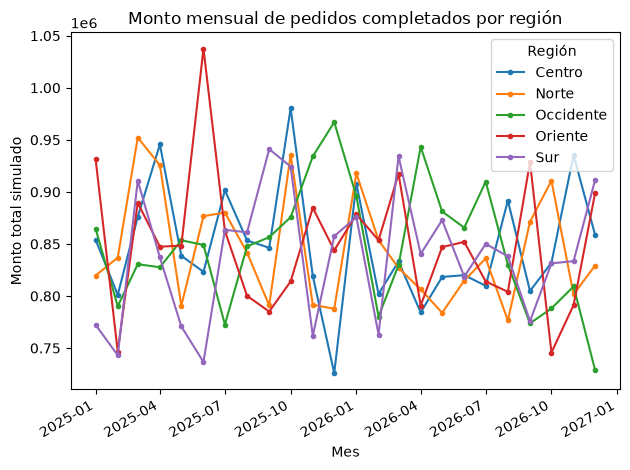

In [10]:
fig, ax = plt.subplots()
for region, grupo in ventas_mensuales.groupby("region"):
    grupo = grupo.sort_values("mes")
    ax.plot(grupo["mes"], grupo["monto_total"], marker=".", label=region)

ax.set(
    title="Monto mensual de pedidos completados por región",
    xlabel="Mes",
    ylabel="Monto total simulado"
)
ax.legend(title="Región")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

**Interpretación:** cada línea representa una región y cada punto corresponde a un mes. Los ascensos y descensos muestran cambios en los montos simulados.

### Gráfico 3. Variación mensual (MoM %) por región

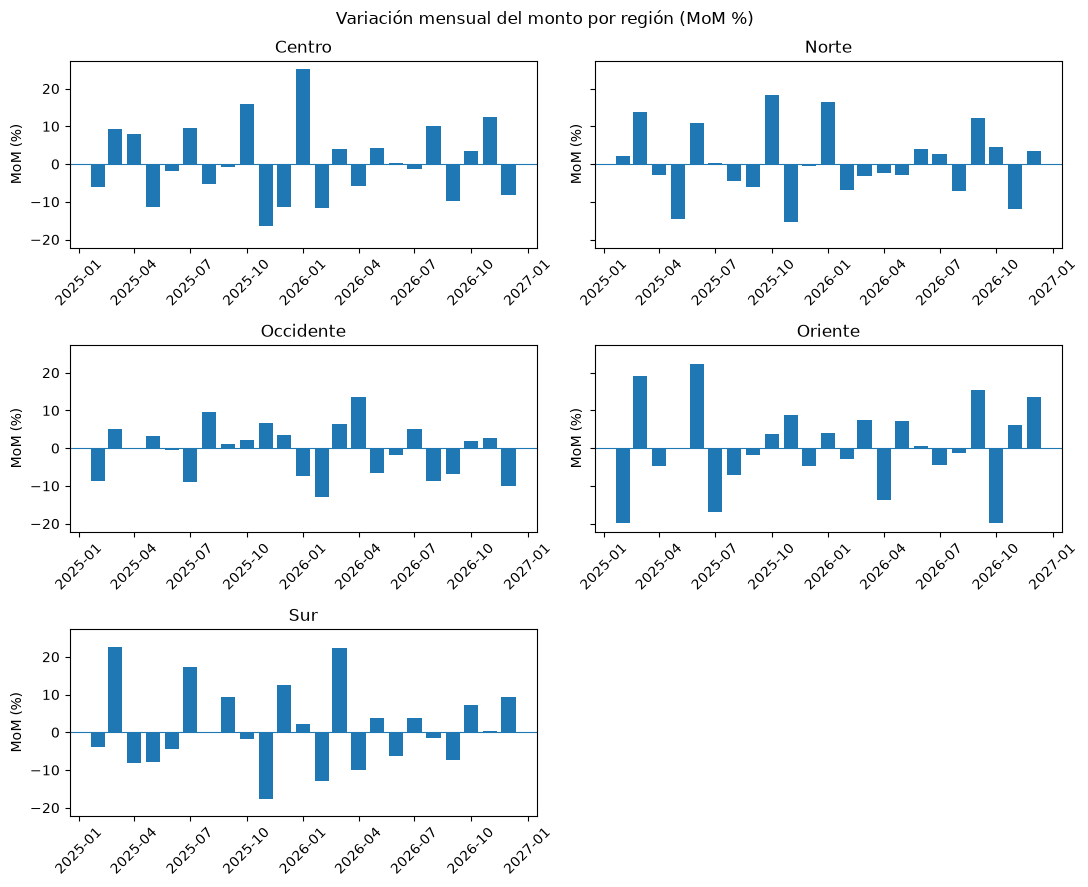

In [11]:
regiones = sorted(analisis_crecimiento_mensual["region"].unique())
fig, ejes = plt.subplots(3, 2, figsize=(11, 9), sharey=True)
ejes = ejes.ravel()

for eje, region in zip(ejes, regiones):
    grupo = analisis_crecimiento_mensual.loc[
        analisis_crecimiento_mensual["region"] == region
    ].dropna(subset=["crecimiento_mensual_pct"])

    eje.bar(grupo["mes"], grupo["crecimiento_mensual_pct"], width=23)
    eje.axhline(0, linewidth=0.8)
    eje.set_title(region)
    eje.tick_params(axis="x", labelrotation=45)
    eje.set_ylabel("MoM (%)")

for eje in ejes[len(regiones):]:
    eje.set_visible(False)

fig.suptitle("Variación mensual del monto por región (MoM %)")
fig.tight_layout()
plt.show()

**Interpretación:** las barras por encima de cero indican aumento respecto al mes anterior; las barras por debajo indican disminución. No hay barra para el primer mes de cada región porque no existe un período anterior.

## 1.8 Comprobar los resultados

**Propósito:** verificar dos condiciones: que la tabla tenga las dimensiones previstas y que el total de pedidos completados coincida antes y después de agrupar.

In [12]:
assert datos_ventas.shape == (50000, 12), "Dimensiones inesperadas"

total_directo = datos_limpios.loc[
    datos_limpios["estado_pedido"] == "Completado",
    "monto_venta_numerico"
].sum()

total_agrupado = ventas_mensuales["monto_total"].sum()

print("Total directo:", total_directo)
print("Total agrupado:", total_agrupado)
print("¿Coinciden?", np.isclose(total_directo, total_agrupado))

Total directo: 101467073.92
Total agrupado: 101467073.91999999
¿Coinciden? True


`assert` detiene la ejecución si la condición no se cumple; `np.isclose()` comprueba que dos números sean suficientemente próximos, teniendo en cuenta pequeñas diferencias de cálculo decimal.

**Al terminar:** habrás creado tres objetos principales: `datos_ventas` (tabla original), `datos_limpios` (tabla con columnas preparadas) y `analisis_crecimiento_mensual` (comparación por mes y región).